# NISAR GCOV → five-class labels → native 20 m PALT (three seeds)

Integrated from your uploaded standalone 05/06 audit and PALT experiment. **Run all in Kaggle with Internet and GPU enabled.** NASA Earthdata and Google Earth Engine authentication may be requested. Allow sufficient disk space for the 7.39 GB scene and intermediate rasters. This creates a **new** experimental protocol; prior unsaved splits and checkpoints are not recovered.

In [1]:
import importlib.util, subprocess, sys
packages={'numpy':'numpy','pandas':'pandas','h5py':'h5py','rasterio':'rasterio',
          'matplotlib':'matplotlib','asf_search':'asf_search','earthaccess':'earthaccess',
          'ee':'earthengine-api','geemap':'geemap'}
missing=[v for k,v in packages.items() if importlib.util.find_spec(k) is None]
if missing:subprocess.check_call([sys.executable,'-m','pip','install','--quiet',*missing])
from pathlib import Path, PurePosixPath
import os,json,hashlib,zipfile,shutil,time,getpass,platform,importlib.metadata
from itertools import combinations
import numpy as np
import pandas as pd
import h5py,rasterio
from rasterio.transform import Affine
from rasterio.warp import reproject,Resampling,transform as transform_coords
from rasterio.merge import merge as rio_merge
from rasterio.windows import Window
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap,BoundaryNorm
from matplotlib.patches import Rectangle,Patch
from IPython.display import display
import asf_search as asf
import earthaccess,ee,geemap

from datetime import datetime,timezone
ORIGINAL04_BLOCK_ASSIGNMENTS=None  # Optional; never required for this standalone run.
MAX_OTHER_CLASS_REVIEW=40
PANELS_PER_CLASS=6
RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
BASE_OUT=Path('/kaggle/working/NISAR_FINAL_05_06_Audit_Review')
OUT=BASE_OUT/RUN_ID
OUT.mkdir(parents=True,exist_ok=False)
DATA_DIR=Path('/kaggle/working/NISAR_FINAL_05_06_DATA')
PREP_DIR=OUT/'prepared_data'
LABEL_DIR=PREP_DIR/'labels'
MANIFEST_DIR=PREP_DIR/'manifests'
TILE_DIR=DATA_DIR/'label_tiles'
for p in [DATA_DIR,PREP_DIR,LABEL_DIR,MANIFEST_DIR,TILE_DIR]:p.mkdir(parents=True,exist_ok=True)
SEARCH_ROOTS=[Path('/kaggle/input'),Path('/kaggle/working')]
EE_PROJECT='ee-2303c50091'
BBOX=(82.05,16.45,82.55,17.10)
NAMES=['Mangrove','Water','Built-up','Cropland','Other vegetation']
CLASS_NAMES=dict(enumerate(NAMES));CLASS_NAMES[255]='Ignore/Unknown'
CHANNELS=['VHVH','VVVV']
POL_LAYERS=CHANNELS
FREQ_GROUP='/science/LSAR/GCOV/grids/frequencyA'
H5_NAME='NISAR_L2_PR_GCOV_031_048_D_080_2005_QPDH_A_20260921T130133_20260921T130207_P05023_N_F_J_001.h5'
PATCH=PATCH_SIZE=64
STRIDE=16
BLOCK_SIZE_PX=512
MIN_SAR_VALID=.80
MIN_KNOWN_FRACTION=.05
MIN_PURITY=.80
CENTER_RADIUS=2
IGNORE=255
SPLITS=['train','val','test']
REVIEW_SEED=42
REVIEW_PER_CLASS=12
GRID_SHAPE=(16632,16992)
GRID_TRANSFORM=Affine(20,0,529200,0,-20,2026800)

def require(ok,message):
    if not ok:raise RuntimeError(message)
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(8*1024*1024),b''):h.update(b)
    return h.hexdigest()
def save_json(value,path):
    Path(path).write_text(json.dumps(value,indent=2,allow_nan=False),encoding='utf-8')
def contained_in_block(row,col,patch=64,block=512):
    return row//block==(row+patch-1)//block and col//block==(col+patch-1)//block
save_json({'python':platform.python_version(),'packages':{v:importlib.metadata.version(v) for v in packages.values()}},OUT/'environment.json')
print('NISAR 05+06 COMBINED — preparing and reviewing data within this runtime')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.6/133.6 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.7/78.7 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 9.0 MB/s eta 0:00:00
NISAR 05+06 COMBINED — preparing and reviewing data within this runtime


In [2]:
def usable_h5(path):
    try:
        with h5py.File(path, 'r') as f:
            return FREQ_GROUP in f and all((ch in f[FREQ_GROUP] for ch in CHANNELS))
    except (OSError, KeyError):
        return False
local_candidates = sorted({p for root in SEARCH_ROOTS if root.exists() for p in root.rglob(H5_NAME)})
valid_candidates = [p for p in local_candidates if usable_h5(p)]
H5_FILE = valid_candidates[0] if valid_candidates else None
if H5_FILE is None:
    print('Searching ASF for the exact GCOV product...')
    results = asf.search(granule_list=[Path(H5_NAME).stem])
    matches = [r for r in results if str(r.properties.get('fileName', '')) == H5_NAME or str(r.properties.get('sceneName', '')) == Path(H5_NAME).stem]
    if not matches:
        results = asf.search(platform=['NISAR'], processingLevel=['GCOV'], start='2026-09-21T12:55:00Z', end='2026-09-21T13:10:00Z', intersectsWith='POLYGON((82.05 16.45,82.55 16.45,82.55 17.10,82.05 17.10,82.05 16.45))', maxResults=50)
        matches = [r for r in results if str(r.properties.get('fileName', '')) == H5_NAME or str(r.properties.get('sceneName', '')) == Path(H5_NAME).stem]
    require(len(matches) >= 1, 'Exact GCOV product unavailable from ASF. No alternative acquisition will be used.')
    chosen = matches[0]
    url = chosen.properties.get('url')
    require(bool(url), 'ASF did not return a download URL for the exact product.')
    save_json(dict(chosen.properties), PREP_DIR / 'asf_product.json')
    print('Product:', H5_NAME)
    print('Authenticate with NASA Earthdata when prompted. Credentials are not saved in results.')
    earthaccess.login(strategy='interactive', persist=False)
    destination = DATA_DIR / H5_NAME
    if destination.exists() and (not usable_h5(destination)):
        destination.rename(DATA_DIR / (H5_NAME + '.incomplete_' + str(time.time_ns())))
    try:
        earthaccess.download([url], str(DATA_DIR))
    except Exception as e:
        print('Earthaccess download did not complete:', type(e).__name__)
    if not usable_h5(destination):
        if destination.exists():
            destination.rename(DATA_DIR / (H5_NAME + '.incomplete_' + str(time.time_ns())))
        print('Retrying the same product through ASF authenticated download.')
        username = input('Earthdata username: ')
        password = getpass.getpass('Earthdata password: ')
        session = asf.ASFSession().auth_with_creds(username, password)
        del password
        chosen.download(path=str(DATA_DIR), session=session)
        del session, username
    require(usable_h5(destination), 'Download is missing or incomplete. Check Earthdata access and available Kaggle disk space.')
    H5_FILE = destination
print('NISAR HDF5:', H5_FILE)


Searching ASF for the exact GCOV product...
Product: NISAR_L2_PR_GCOV_031_048_D_080_2005_QPDH_A_20260921T130133_20260921T130207_P05023_N_F_J_001.h5
Authenticate with NASA Earthdata when prompted. Credentials are not saved in results.


Enter your Earthdata Login username:  karunasri
Enter your Earthdata password:  ········


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

NISAR HDF5: /kaggle/working/NISAR_FINAL_05_06_DATA/NISAR_L2_PR_GCOV_031_048_D_080_2005_QPDH_A_20260921T130133_20260921T130207_P05023_N_F_J_001.h5


In [3]:
require(H5_FILE.is_file() and H5_FILE.name == H5_NAME, 'Wrong or missing frozen HDF5 acquisition.')
with h5py.File(H5_FILE, 'r') as f:
    require(FREQ_GROUP in f, f'Missing HDF5 group {FREQ_GROUP}')
    g = f[FREQ_GROUP]
    for key in CHANNELS + ['xCoordinates', 'yCoordinates', 'projection']:
        require(key in g, f'Missing Frequency-A dataset: {key}')
    shape = g[CHANNELS[0]].shape
    require(shape == (16632, 16992), f'Unexpected frozen-product grid: {shape}')
    for ch in CHANNELS:
        require(g[ch].shape == shape and np.issubdtype(g[ch].dtype, np.floating), f'Invalid real power layer: {ch}')
    x = np.asarray(g['xCoordinates'][:], dtype=np.float64)
    y = np.asarray(g['yCoordinates'][:], dtype=np.float64)
    require(x.shape == (shape[1],) and y.shape == (shape[0],), 'Coordinate dimensions mismatch.')
    require(np.allclose(np.diff(x), 20) and np.allclose(np.diff(y), -20), 'Unexpected grid spacing.')
    transform = Affine(20, 0, x[0] - 10, 0, -20, y[0] + 10)
    require(np.allclose(tuple(transform), tuple(Affine(20, 0, 529200, 0, -20, 2026800))), 'Unexpected grid origin.')
    proj = g['projection']
    epsg = None
    for key in ['epsg_code', 'epsgCode', 'EPSG']:
        if key in proj.attrs:
            epsg = int(np.asarray(proj.attrs[key]).item())
            break
    if epsg is None:
        value = np.asarray(proj[()])
        if value.size == 1 and np.issubdtype(value.dtype, np.number):
            epsg = int(value.item())
    require(epsg == 32644, f'Unverified projection EPSG: {epsg}')
height, width = shape
dx, dy = (20.0, -20.0)
nisar_crs = rasterio.crs.CRS.from_epsg(epsg)
print('Frequency-A checked:', shape, CHANNELS, 'EPSG', epsg)
print('Computing the original HDF5 fingerprint (one sequential file read)...')
H5_SHA256 = sha256(H5_FILE)
save_json({'h5_path': str(H5_FILE), 'h5_name': H5_NAME, 'sha256': H5_SHA256, 'size_bytes': H5_FILE.stat().st_size, 'frequency_group': FREQ_GROUP, 'channels': CHANNELS, 'shape': list(shape), 'epsg': epsg, 'transform': list(transform)}, PREP_DIR / 'acquisition.json')


Frequency-A checked: (16632, 16992) ['VHVH', 'VVVV'] EPSG 32644
Computing the original HDF5 fingerprint (one sequential file read)...


In [4]:

# ============================================================
# RESTORE ORIGINAL NISAR 5-CLASS label_export
# Kaggle / Google Earth Engine
# ============================================================

import ee
import json
from pathlib import Path

PROJECT_ID = "ee-2303c50091"
BBOX = (82.05, 16.45, 82.55, 17.10)

ROOT = Path("/kaggle/working/NISAR_FINAL_05_06_DATA")
ROOT.mkdir(parents=True, exist_ok=True)

# 1. Initialize Earth Engine
try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate(auth_mode="notebook")
    ee.Initialize(project=PROJECT_ID)

print("Earth Engine connected:", ee.Number(10).getInfo())

# 2. Original study area and data sources
AOI = ee.Geometry.Rectangle(
    list(BBOX), proj="EPSG:4326", geodesic=False
)

DW_START = "2026-06-17"
DW_END = "2026-09-22"

wc = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
)

dw = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterBounds(AOI)
    .filterDate(DW_START, DW_END)
)

dw_count = dw.size().getInfo()
print("Dynamic World images:", dw_count)

if dw_count == 0:
    raise RuntimeError(
        "No Dynamic World images for the original date window."
    )

prob_bands = [
    "water", "trees", "grass",
    "flooded_vegetation", "crops",
    "shrub_and_scrub", "built"
]

dwp = dw.select(prob_bands).median()

jrc = (
    ee.Image("JRC/GSW1_4/GlobalSurfaceWater")
    .select("occurrence")
)

# 3. Class probabilities
p_water = dwp.select("water")
p_tree = dwp.select("trees")
p_grass = dwp.select("grass")
p_shrub = dwp.select("shrub_and_scrub")
p_crop = dwp.select("crops")
p_built = dwp.select("built")

veg_prob = p_tree.max(p_grass).max(p_shrub)

# Original thresholds
TH_WATER = 0.65
TH_BUILT = 0.50
TH_CROP = 0.30
TH_VEG = 0.40

# 4. Five-class reference-label rules
mangrove = wc.eq(95)

water = (
    p_water.gte(TH_WATER)
    .And(wc.eq(80).Or(jrc.gte(75)))
    .And(mangrove.Not())
)

built = (
    p_built.gte(TH_BUILT)
    .And(wc.eq(50))
    .And(mangrove.Not())
)

crop = (
    p_crop.gte(TH_CROP)
    .And(wc.eq(40))
    .And(mangrove.Not())
)

otherveg = (
    veg_prob.gte(TH_VEG)
    .And(wc.eq(10).Or(wc.eq(20)).Or(wc.eq(30)))
    .And(mangrove.Not())
)

# 5. Scientific class encoding:
# 0 Mangrove
# 1 Water
# 2 Built-up
# 3 Cropland
# 4 Other vegetation
# 255 Ignore

label = ee.Image.constant(255).toUint8().clip(AOI)

label = label.where(otherveg, 4)
label = label.where(crop, 3)
label = label.where(built, 2)
label = label.where(water, 1)
label = label.where(mangrove, 0)

label = (
    label.unmask(255)
    .toUint8()
    .rename("reference_label")
)

# 6. Safe export encoding:
# 1 Mangrove
# 2 Water
# 3 Built-up
# 4 Cropland
# 5 Other vegetation
# 255 Ignore

label_export = (
    label.remap(
        [0, 1, 2, 3, 4, 255],
        [1, 2, 3, 4, 5, 255],
        255
    )
    .unmask(255)
    .toUint8()
    .rename("reference_label_export")
)

# 7. Validate labels
hist = label_export.reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=AOI,
    scale=10,
    maxPixels=1e9,
    bestEffort=True
).get("reference_label_export").getInfo()

print("\nSafe label histogram:", hist)

found = {int(float(k)) for k in hist.keys()}
assert {1, 2, 3, 4, 5}.issubset(found), (
    "Not all five classes are present."
)

# 8. Save provenance
config = {
    "bbox": list(BBOX),
    "dynamic_world_start": DW_START,
    "dynamic_world_end": DW_END,
    "sources": {
        "DynamicWorld": "GOOGLE/DYNAMICWORLD/V1",
        "WorldCover": "ESA/WorldCover/v200",
        "JRCWater": "JRC/GSW1_4/GlobalSurfaceWater"
    },
    "thresholds": {
        "water": TH_WATER,
        "built": TH_BUILT,
        "crop": TH_CROP,
        "vegetation": TH_VEG
    },
    "safe_encoding": {
        "1": "Mangrove",
        "2": "Water",
        "3": "Built-up",
        "4": "Cropland",
        "5": "Other vegetation",
        "255": "Ignore"
    },
    "label_type": "Multi-source pseudo-reference labels"
}

config_path = ROOT / "restored_label_config.json"
config_path.write_text(json.dumps(config, indent=2))

print("\n" + "=" * 60)
print("SUCCESS: label_export CREATED")
print("=" * 60)
print("Image type:", type(label_export))
print("Configuration:", config_path)
print("Next: Run the 16-tile download cell.")


To authorize access needed by Earth Engine, open the following URL in a web browser and follow the instructions. If the web browser does not start automatically, please manually browse the URL below.

    https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_control&request_id=fe_8clm8f7qBLFD-ZBGK5rOSvHqSKb6E86kk9Df2f9I&tc=nxcQlF_31hE6wIcKeZzurElFgcyOtjArlmLfREJ3hJg&cc=T_SCdggCeojQIXQl-JHHA_bRzTXVJXrfI_V4m_0Lapg

The authorization workflow will generate a code, which you should paste in the box below.


Enter verification code:  4/1AXlqoi6aU-5PDKmfX7tAnr7I0W_jpBXhsCtN86y6bXJRi4ExW-lXUbzKT0k



Successfully saved authorization token.
Earth Engine connected: 10
Dynamic World images: 10

Safe label histogram: {'1': 2203222, '2': 17689349.38431377, '255': 18627723.588235237, '3': 124826.53725490197, '4': 1120140.4470588244, '5': 509395.1098039215}

SUCCESS: label_export CREATED
Image type: <class 'ee.image.Image'>
Configuration: /kaggle/working/NISAR_FINAL_05_06_DATA/restored_label_config.json
Next: Run the 16-tile download cell.


In [5]:

# ============================================================
# NISAR 5-CLASS LABEL TILE DOWNLOAD — SAFE KAGGLE VERSION
# ============================================================

import os
import time
import requests
import rasterio
import ee

from pathlib import Path

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

PROJECT_ID = "ee-2303c50091"

ROOT = Path("/kaggle/working/NISAR_FINAL_05_06_DATA")
TILE_DIR = ROOT / "label_tiles"
TILE_DIR.mkdir(parents=True, exist_ok=True)

BBOX = (82.05, 16.45, 82.55, 17.10)
N = 4
MAX_RETRIES = 5

# ------------------------------------------------------------
# VALIDATE EXISTING TILES
# ------------------------------------------------------------

def valid_tile(path):
    if not path.exists():
        return False

    try:
        with rasterio.open(path) as src:
            return (
                src.count == 1
                and src.width > 100
                and src.height > 100
                and src.crs is not None
                and abs(src.transform.a) > 0
                and abs(src.transform.e) > 0
            )
    except Exception:
        return False


tile_paths = [
    TILE_DIR / f"labels_r{r}_c{c}.tif"
    for r in range(N)
    for c in range(N)
]

existing = sum(valid_tile(p) for p in tile_paths)

print("=" * 60)
print("NISAR LABEL TILE STATUS")
print("=" * 60)
print(f"Existing valid tiles: {existing}/{N*N}")

# ------------------------------------------------------------
# CHECK FOR PREVIOUSLY PREPARED REFERENCE LABELS
# ------------------------------------------------------------

aligned_label = ROOT / "reference_labels_5class_SAR20m.tif"

if aligned_label.exists():
    print("\nPreviously prepared SAR-aligned labels found:")
    print(aligned_label)
    print(
        "Note: You may not need to download tiles "
        "if continuing the existing experiment."
    )

# ------------------------------------------------------------
# EARTH ENGINE INITIALIZATION ONLY IF NEEDED
# ------------------------------------------------------------

if existing < N * N:

    print("\nInitializing Earth Engine...")

    try:
        ee.Initialize(project=PROJECT_ID)

    except Exception:
        ee.Authenticate(auth_mode="notebook")
        ee.Initialize(project=PROJECT_ID)

    print("Earth Engine initialized.")
    print("Connection test:", ee.Number(10).getInfo())

    # --------------------------------------------------------
    # VERIFY ORIGINAL LABEL IMAGE
    # --------------------------------------------------------

    if "label_export" not in globals():

        raise RuntimeError(
            "\nMISSING: label_export\n\n"
            "Earth Engine is working, but the original "
            "five-class label image has not been defined "
            "in this Kaggle session.\n\n"
            "Run the original Earth Engine label-generation "
            "cell before running this downloader.\n\n"
            "The downloader cannot reconstruct the original "
            "reference labels without their source datasets "
            "and class-mapping rules.\n\n"
            "No existing files have been overwritten."
        )

    if not isinstance(label_export, ee.image.Image):
        raise TypeError(
            "label_export must be an ee.Image."
        )

    print("Original label_export image is available.")

    # --------------------------------------------------------
    # DOWNLOAD MISSING TILES
    # --------------------------------------------------------

    minx, miny, maxx, maxy = BBOX

    dx = (maxx - minx) / N
    dy = (maxy - miny) / N

    for r in range(N):
        for c in range(N):

            fp = TILE_DIR / f"labels_r{r}_c{c}.tif"

            if valid_tile(fp):
                print("REUSED:", fp.name)
                continue

            x0 = minx + c * dx
            x1 = minx + (c + 1) * dx
            y0 = miny + r * dy
            y1 = miny + (r + 1) * dy

            region = ee.Geometry.Rectangle(
                [x0, y0, x1, y1],
                proj="EPSG:4326",
                geodesic=False
            )

            print("\nDownloading:", fp.name)

            success = False

            for attempt in range(1, MAX_RETRIES + 1):

                temp = fp.with_suffix(".tmp")

                try:
                    url = label_export.getDownloadURL({
                        "region": region,
                        "scale": 10,
                        "format": "GEO_TIFF"
                    })

                    with requests.get(
                        url,
                        stream=True,
                        timeout=(30, 300)
                    ) as response:

                        response.raise_for_status()

                        with open(temp, "wb") as f:
                            for chunk in response.iter_content(
                                chunk_size=1024 * 1024
                            ):
                                if chunk:
                                    f.write(chunk)

                    if not valid_tile(temp):
                        raise RuntimeError(
                            "Downloaded GeoTIFF failed validation."
                        )

                    os.replace(temp, fp)

                    print("SUCCESS:", fp.name)
                    success = True
                    break

                except Exception as e:
                    print(
                        f"Attempt {attempt}/{MAX_RETRIES}:",
                        str(e)[:200]
                    )

                    if temp.exists():
                        temp.unlink()

                    if attempt < MAX_RETRIES:
                        time.sleep(min(10 * attempt, 60))

            if not success:
                raise RuntimeError(
                    f"Failed to download {fp.name}. "
                    "Previously valid tiles were preserved."
                )

else:
    print("\nAll tiles exist. No Earth Engine call needed.")

# ------------------------------------------------------------
# FINAL VERIFICATION
# ------------------------------------------------------------

valid_count = sum(valid_tile(p) for p in tile_paths)

print("\n" + "=" * 60)
print("FINAL VERIFICATION")
print("=" * 60)

for fp in tile_paths:
    status = "OK" if valid_tile(fp) else "MISSING/INVALID"
    print(f"{fp.name}: {status}")

print(f"\nCompleted: {valid_count}/{N*N} tiles")

assert valid_count == N*N, "Tile preparation incomplete."

print("\nSUCCESS: All label tiles are available.")
print("Directory:", TILE_DIR)


NISAR LABEL TILE STATUS
Existing valid tiles: 0/16

Initializing Earth Engine...
Earth Engine initialized.
Connection test: 10
Original label_export image is available.

Downloading: labels_r0_c0.tif
SUCCESS: labels_r0_c0.tif

Downloading: labels_r0_c1.tif
SUCCESS: labels_r0_c1.tif

Downloading: labels_r0_c2.tif
SUCCESS: labels_r0_c2.tif

Downloading: labels_r0_c3.tif
SUCCESS: labels_r0_c3.tif

Downloading: labels_r1_c0.tif
SUCCESS: labels_r1_c0.tif

Downloading: labels_r1_c1.tif
SUCCESS: labels_r1_c1.tif

Downloading: labels_r1_c2.tif
SUCCESS: labels_r1_c2.tif

Downloading: labels_r1_c3.tif
SUCCESS: labels_r1_c3.tif

Downloading: labels_r2_c0.tif
SUCCESS: labels_r2_c0.tif

Downloading: labels_r2_c1.tif
SUCCESS: labels_r2_c1.tif

Downloading: labels_r2_c2.tif
SUCCESS: labels_r2_c2.tif

Downloading: labels_r2_c3.tif
SUCCESS: labels_r2_c3.tif

Downloading: labels_r3_c0.tif
SUCCESS: labels_r3_c0.tif

Downloading: labels_r3_c1.tif
SUCCESS: labels_r3_c1.tif

Downloading: labels_r3_c2.tif
SU

## Create a native 20 m, class-consensus label raster
The 10 m label raster is aligned to SAR 20 m pixels by 2×2 majority voting. At least three of four 10 m samples must agree; otherwise the 20 m pixel becomes Ignore (255). The 10 m source remains unchanged.

In [6]:
import numpy as np
import rasterio
import h5py

from pathlib import Path
from contextlib import ExitStack
from affine import Affine
from rasterio.io import MemoryFile
from rasterio.merge import merge
from rasterio.warp import reproject, Resampling, transform_bounds

ROOT = Path("/kaggle/working/NISAR_FINAL_05_06_DATA")
TILES = ROOT / "label_tiles"

LABEL10 = ROOT / "reference_labels_5class.tif"
LABEL20 = ROOT / "reference_labels_5class_SAR20m.tif"

# 1. Check all 16 original tiles
tile_paths = [
    TILES / f"labels_r{r}_c{c}.tif"
    for r in range(4)
    for c in range(4)
]

missing = [p.name for p in tile_paths if not p.exists()]

if missing:
    raise RuntimeError(
        f"Missing {len(missing)} tiles: {missing}. "
        "Finish the tile-download cell first."
    )

print("All 16 tiles found.")

# 2. Read NISAR's native grid
h5_files = list(ROOT.glob("*.h5"))
assert h5_files, "NISAR HDF5 file not found."

with h5py.File(h5_files[0], "r") as f:
    g = f["science/LSAR/GCOV/grids/frequencyA"]

    x = g["xCoordinates"]
    y = g["yCoordinates"]

    dx = float(x[1] - x[0])
    dy = float(y[1] - y[0])

    sar_tf = Affine(
        dx, 0, float(x[0]) - dx / 2,
        0, dy, float(y[0]) - dy / 2
    )

    sar_crs = rasterio.crs.CRS.from_epsg(
        int(g["projection"][()])
    )

# 3. Normalize and merge original tiles
with ExitStack() as stack:
    sources = []

    for path in tile_paths:
        src = stack.enter_context(rasterio.open(path))

        arr = src.read(1)
        tf = src.transform

        if tf.e > 0:
            arr = np.flipud(arr)
            tf = (
                tf
                * Affine.translation(0, src.height)
                * Affine.scale(1, -1)
            )

        if tf.a < 0:
            arr = np.fliplr(arr)
            tf = (
                tf
                * Affine.translation(src.width, 0)
                * Affine.scale(-1, 1)
            )

        # Earth Engine safe codes: 1..5
        arr = np.where(
            np.isin(arr, [1, 2, 3, 4, 5]),
            arr,
            255
        ).astype(np.uint8)

        mem = stack.enter_context(MemoryFile())

        profile = src.profile.copy()
        profile.update(
            transform=tf,
            dtype="uint8",
            count=1,
            nodata=255
        )

        dst = stack.enter_context(mem.open(**profile))
        dst.write(arr, 1)
        sources.append(dst)

    mosaic, mosaic_tf = merge(
        sources,
        nodata=255,
        resampling=Resampling.nearest
    )

    mosaic_crs = sources[0].crs

print("Merged mosaic:", mosaic.shape)

# 4. Build NISAR-aligned target grid
bounds = rasterio.transform.array_bounds(
    mosaic.shape[1],
    mosaic.shape[2],
    mosaic_tf
)

left, bottom, right, top = transform_bounds(
    mosaic_crs,
    sar_crs,
    *bounds,
    densify_pts=21
)

col0 = int(np.floor((left - sar_tf.c) / 20))
col1 = int(np.ceil((right - sar_tf.c) / 20))

row0 = int(np.floor((sar_tf.f - top) / 20))
row1 = int(np.ceil((sar_tf.f - bottom) / 20))

H = row1 - row0
W = col1 - col0

assert H > 100 and W > 100, "Invalid target dimensions."

tf20 = sar_tf * Affine.translation(col0, row0)
tf10 = tf20 * Affine.scale(0.5, 0.5)

# 5. Reproject to 10 m
safe10 = np.full(
    (H * 2, W * 2),
    255,
    dtype=np.uint8
)

reproject(
    source=mosaic[0],
    destination=safe10,
    src_transform=mosaic_tf,
    src_crs=mosaic_crs,
    src_nodata=255,
    dst_transform=tf10,
    dst_crs=sar_crs,
    dst_nodata=255,
    resampling=Resampling.nearest
)

labels10 = np.full(safe10.shape, 255, dtype=np.uint8)

for k in range(1, 6):
    labels10[safe10 == k] = k - 1

# 6. Aggregate 10 m to 20 m using 3-of-4 consensus
blocks = labels10.reshape(H, 2, W, 2)
blocks = blocks.transpose(0, 2, 1, 3)
blocks = blocks.reshape(H, W, 4)

counts = np.stack(
    [(blocks == k).sum(axis=2) for k in range(5)],
    axis=0
)

labels20 = np.where(
    counts.max(axis=0) >= 3,
    counts.argmax(axis=0),
    255
).astype(np.uint8)

# 7. Validate both rasters before saving
for name, arr in [
    ("10 m", labels10),
    ("20 m", labels20)
]:
    values, frequencies = np.unique(
        arr,
        return_counts=True
    )

    histogram = dict(
        zip(values.tolist(), frequencies.tolist())
    )

    print(f"\n{name} shape:", arr.shape)
    print(f"{name} histogram:", histogram)

    assert set(range(5)).issubset(set(values.tolist())), (
        f"{name} labels are missing one or more classes."
    )

# 8. Save GeoTIFFs
def save_raster(path, array, tf):
    with rasterio.open(
        path,
        "w",
        driver="GTiff",
        height=array.shape[0],
        width=array.shape[1],
        count=1,
        dtype="uint8",
        crs=sar_crs,
        transform=tf,
        nodata=255,
        compress="lzw"
    ) as dst:
        dst.write(array, 1)

save_raster(LABEL10, labels10, tf10)
save_raster(LABEL20, labels20, tf20)

print("\nSUCCESS — BOTH LABEL FILES CREATED")
print("10 m:", LABEL10)
print("20 m:", LABEL20)
print("Ready for NISAR PALT training.")

All 16 tiles found.
Merged mosaic: (1, 7237, 5567)

10 m shape: (7232, 5380)
10 m histogram: {0: 2097772, 1: 16846891, 2: 118635, 3: 1066846, 4: 484602, 255: 18293414}

20 m shape: (3616, 2690)
20 m histogram: {0: 519718, 1: 4198035, 2: 25979, 3: 250423, 4: 113935, 255: 4618950}

SUCCESS — BOTH LABEL FILES CREATED
10 m: /kaggle/working/NISAR_FINAL_05_06_DATA/reference_labels_5class.tif
20 m: /kaggle/working/NISAR_FINAL_05_06_DATA/reference_labels_5class_SAR20m.tif
Ready for NISAR PALT training.


In [7]:
from pathlib import Path
import rasterio
import numpy as np

DATA_DIR = Path("/kaggle/working/NISAR_FINAL_05_06_DATA")

LABEL_FILE = DATA_DIR / "reference_labels_5class.tif"
LABEL20_FILE = DATA_DIR / "reference_labels_5class_SAR20m.tif"

for path, resolution in [(LABEL_FILE, 10), (LABEL20_FILE, 20)]:
    assert path.exists(), f"Missing: {path}"

    with rasterio.open(path) as src:
        values, counts = np.unique(src.read(1), return_counts=True)

        assert src.crs.to_epsg() == 32644
        assert np.allclose(src.res, (resolution, resolution))
        assert {0, 1, 2, 3, 4}.issubset(set(values.tolist()))

        print(f"\n{resolution} m labels verified")
        print("Shape:", src.shape)
        print("Transform:", src.transform)
        print("Histogram:", dict(zip(values.tolist(), counts.tolist())))

print("\nSUCCESS: Both reference-label rasters are ready.")


10 m labels verified
Shape: (7232, 5380)
Transform: | 10.00, 0.00, 611700.00|
| 0.00,-10.00, 1891300.00|
| 0.00, 0.00, 1.00|
Histogram: {0: 2097772, 1: 16846891, 2: 118635, 3: 1066846, 4: 484602, 255: 18293414}

20 m labels verified
Shape: (3616, 2690)
Transform: | 20.00, 0.00, 611700.00|
| 0.00,-20.00, 1891300.00|
| 0.00, 0.00, 1.00|
Histogram: {0: 519718, 1: 4198035, 2: 25979, 3: 250423, 4: 113935, 255: 4618950}

SUCCESS: Both reference-label rasters are ready.


## Train and evaluate PALT
The following cells are preserved from the three-seed training notebook. They search for the freshly downloaded HDF5 and the aligned 20 m labels.

In [8]:
import importlib.util, subprocess, sys
need={'numpy':'numpy','pandas':'pandas','h5py':'h5py','rasterio':'rasterio','sklearn':'scikit-learn','torch':'torch','nbformat':'nbformat'}
missing=[v for k,v in need.items() if importlib.util.find_spec(k) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
import os, math, random, json, hashlib, zipfile, time
from pathlib import Path
import numpy as np, pandas as pd, h5py, rasterio, torch
from rasterio.transform import Affine
from sklearn.metrics import (accuracy_score,balanced_accuracy_score,f1_score,precision_score,recall_score,cohen_kappa_score,classification_report,confusion_matrix)
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset,DataLoader,WeightedRandomSampler
ROOT=Path('/kaggle/working/NISAR_FINAL_05_06_DATA')
H5_NAME='NISAR_L2_PR_GCOV_031_048_D_080_2005_QPDH_A_20260921T130133_20260921T130207_P05023_N_F_J_001.h5'
LABEL_NAME='reference_labels_5class_SAR20m.tif'
# Search both persistent Kaggle inputs and current-session working files.
# Do not silently select a different acquisition or a 10 m label raster.
def find_exact(name):
    candidates=[]
    for base in (Path('/kaggle/input'),Path('/kaggle/working')):
        if base.exists():
            candidates.extend(p for p in base.rglob(name) if p.is_file())
    candidates=sorted(
        set(candidates),
        key=lambda p:(
            not str(p).startswith(str(ROOT)),
            str(p).startswith('/kaggle/input'),
            str(p)
        )
    )
    if not candidates:
        raise FileNotFoundError(
            f'Cannot find {name} in /kaggle/input or /kaggle/working.\n'
            'A new Kaggle session does not retain earlier /kaggle/working files.\n'
            'Open the original data-preparation notebook, Save Version with outputs,\n'
            'then use Add Input > Your Work > Notebook Output to attach those files.\n'
            'If the files were never saved as an output, restore them from their original source.'
        )
    if len(candidates)>1:
        print(f'Found {len(candidates)} copies of {name}; selecting {candidates[0]}')
    return candidates[0]
H5_FILE=find_exact(H5_NAME)
LABEL_FILE=find_exact(LABEL_NAME)
print('Resolved HDF5:',H5_FILE)
print('Resolved labels:',LABEL_FILE)
FREQ_GROUP='science/LSAR/GCOV/grids/frequencyA'
CLASS_NAMES=['Mangrove','Water','Built-up','Cropland','Other vegetation']
PATCH=64; STRIDE=16; BLOCK=512; BUFFER=32
MIN_KNOWN=.05; MIN_PURITY=.80; MIN_CENTER_SUPPORT=.80
SEEDS=[42,123,2026]
EPOCHS=25; PATIENCE=5; BATCH_SIZE=64; LR=3e-4; WEIGHT_DECAY=1e-4
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EXP=Path('/kaggle/working/NISAR_PALT_20M_FINAL')
for folder in ['splits','metrics','predictions','checkpoints']:(EXP/folder).mkdir(parents=True,exist_ok=True)
print('Device:',DEVICE,'| H5:',round(H5_FILE.stat().st_size/1e9,2),'GB')


Resolved HDF5: /kaggle/working/NISAR_FINAL_05_06_DATA/NISAR_L2_PR_GCOV_031_048_D_080_2005_QPDH_A_20260921T130133_20260921T130207_P05023_N_F_J_001.h5
Resolved labels: /kaggle/working/NISAR_FINAL_05_06_DATA/reference_labels_5class_SAR20m.tif
Device: cuda | H5: 7.39 GB


## 1. Validate exact SAR/label grid and read only the study-area window

In [9]:
with h5py.File(H5_FILE,'r') as f:
 g=f[FREQ_GROUP]
 assert all(k in g for k in ('VHVH','VVVV','xCoordinates','yCoordinates','projection'))
 x0=float(g['xCoordinates'][0]); y0=float(g['yCoordinates'][0])
 dx=float(g['xCoordinates'][1]-x0); dy=float(g['yCoordinates'][1]-y0)
 assert np.isclose(dx,20) and np.isclose(dy,-20)
 SAR_TRANSFORM=Affine(dx,0,x0-dx/2,0,dy,y0-dy/2)
 assert int(g['projection'][()])==32644
 SAR_SHAPE=g['VVVV'].shape
with rasterio.open(LABEL_FILE) as src:
 assert src.crs.to_epsg()==32644 and src.res==(20.0,20.0) and src.nodata==255
 labels=src.read(1); label_transform=src.transform
 assert set(np.unique(labels).tolist()).issubset({0,1,2,3,4,255})
col_offset=(label_transform.c-SAR_TRANSFORM.c)/20
row_offset=(SAR_TRANSFORM.f-label_transform.f)/20
assert np.isclose(col_offset,round(col_offset)) and np.isclose(row_offset,round(row_offset))
ROW0=int(round(row_offset)); COL0=int(round(col_offset))
H,W=labels.shape
assert ROW0>=0 and COL0>=0 and ROW0+H<=SAR_SHAPE[0] and COL0+W<=SAR_SHAPE[1]
assert np.allclose(tuple(SAR_TRANSFORM*Affine.translation(COL0,ROW0)),tuple(label_transform))
with h5py.File(H5_FILE,'r') as f:
 g=f[FREQ_GROUP]
 vv=g['VVVV'][ROW0:ROW0+H,COL0:COL0+W]
 vh=g['VHVH'][ROW0:ROW0+H,COL0:COL0+W]
 valid=np.isfinite(vv)&np.isfinite(vh)&(vv>0)&(vh>0)
 assert valid[labels!=255].all(),'Some labeled pixels have invalid SAR'
 del vv,vh
print('Label shape:',(H,W),'| SAR offset:',(ROW0,COL0),'| labeled valid:',int((labels!=255).sum()))


Label shape: (3616, 2690) | SAR offset: (6775, 4125) | labeled valid: 5108090


## 2. Generate class-pure, block-buffered 64×64 patches (new frozen manifest)

In [10]:
# Efficient summed-area tables for class counts; no SAR image is copied into the manifest.
# A patch must lie entirely within the 32-pixel inset of one 512-pixel block.
# Thus footprints in adjacent assigned blocks are separated by >=64 pixels.
def summed_area(mask):
 a=np.zeros((H+1,W+1),dtype=np.uint32)
 a[1:,1:]=mask.astype(np.uint32)
 np.cumsum(a[1:,1:],axis=0,out=a[1:,1:]); np.cumsum(a[1:,1:],axis=1,out=a[1:,1:])
 return a
rows=[]; cols=[]; blockids=[]
for br in range((H+BLOCK-1)//BLOCK):
 for bc in range((W+BLOCK-1)//BLOCK):
  lo_r=br*BLOCK+BUFFER; hi_r=min((br+1)*BLOCK,H)-BUFFER-PATCH
  lo_c=bc*BLOCK+BUFFER; hi_c=min((bc+1)*BLOCK,W)-BUFFER-PATCH
  if lo_r>hi_r or lo_c>hi_c:continue
  for r in range(((lo_r+STRIDE-1)//STRIDE)*STRIDE,hi_r+1,STRIDE):
   for c in range(((lo_c+STRIDE-1)//STRIDE)*STRIDE,hi_c+1,STRIDE):
    if int(labels[r+PATCH//2,c+PATCH//2]) not in range(5):continue
    rows.append(r); cols.append(c); blockids.append(f'{br}_{bc}')
assert rows,'No candidate patches: inspect labels and block/buffer settings'
rows=np.asarray(rows,dtype=np.int32); cols=np.asarray(cols,dtype=np.int32)
center=labels[rows+PATCH//2,cols+PATCH//2]
counts=np.zeros((len(rows),5),dtype=np.uint16)
for cls in range(5):
 a=summed_area(labels==cls)
 rr=rows.astype(np.int64);cc=cols.astype(np.int64)
 counts[:,cls]=(a[rr+PATCH,cc+PATCH].astype(np.int64)-a[rr,cc+PATCH].astype(np.int64)-a[rr+PATCH,cc].astype(np.int64)+a[rr,cc].astype(np.int64)).astype(np.uint16)
 del a
known=counts.sum(axis=1)
purity=counts[np.arange(len(rows)),center]/np.maximum(known,1)
center_support=np.zeros(len(rows),dtype=np.float32)
for dr in range(-2,3):
 for dc in range(-2,3):center_support+=(labels[rows+PATCH//2+dr,cols+PATCH//2+dc]==center)
center_support/=25
eligible_mask=(known>=MIN_KNOWN*PATCH*PATCH)&(purity>=MIN_PURITY)&(center_support>=MIN_CENTER_SUPPORT)
# Already verified valid SAR on every labeled pixel; require >=80% finite positive SAR in each patch.
valid_integral=summed_area(valid)
rr=rows.astype(np.int64);cc=cols.astype(np.int64)
valid_counts=(valid_integral[rr+PATCH,cc+PATCH].astype(np.int64)-valid_integral[rr,cc+PATCH].astype(np.int64)-valid_integral[rr+PATCH,cc].astype(np.int64)+valid_integral[rr,cc].astype(np.int64))
eligible_mask &= valid_counts>=.80*PATCH*PATCH
del valid_integral,valid
idx=np.flatnonzero(eligible_mask)
data=pd.DataFrame({'patch_id':idx,'row':ROW0+rows[idx],'col':COL0+cols[idx],
 'class_id':center[idx].astype(int),'block_id':np.asarray(blockids)[idx],
 'known_fraction':known[idx]/(PATCH*PATCH),'purity':purity[idx],
 'center_support':center_support[idx],'sar_valid_fraction':valid_counts[idx]/(PATCH*PATCH)})
assert set(data.class_id)==set(range(5)),'Eligibility removed a class; review thresholds, do not silently relax them.'
print('Candidates:',len(rows),'| Eligible:',len(data),'| Blocks:',data.block_id.nunique())
print(data.class_id.value_counts().sort_index().rename(index=dict(enumerate(CLASS_NAMES))))


Candidates: 11506 | Eligible: 10508 | Blocks: 40
class_id
Mangrove            1110
Water               9022
Built-up               3
Cropland             265
Other vegetation     108
Name: count, dtype: int64


## 3. Freeze block-disjoint 70/15/15 approximate split (train/val/test)

In [11]:
import numpy as np
import pandas as pd

block_counts = (
    pd.crosstab(data.block_id, data.class_id)
    .reindex(columns=range(5), fill_value=0)
)

print("Total patches:", len(data))
print("Total spatial blocks:", len(block_counts))

print("\nPatches per class:")
print(data.class_id.value_counts().sort_index())

print("\nSpatial blocks containing each class:")
print((block_counts > 0).sum(axis=0))

print("\nClass coverage by block:")
print(block_counts.to_string())

rare_classes = (block_counts > 0).sum(axis=0)

for cls, n in rare_classes.items():
    if n < 3:
        print(
            f"WARNING: Class {cls} occurs in only {n} "
            "spatial blocks. Three-way splitting is impossible "
            "with the current block definitions."
        )

Total patches: 10508
Total spatial blocks: 40

Patches per class:
class_id
0    1110
1    9022
2       3
3     265
4     108
Name: count, dtype: int64

Spatial blocks containing each class:
class_id
0     7
1    31
2     2
3    12
4     8
dtype: int64

Class coverage by block:
class_id    0    1  2    3   4
block_id                      
0_0         0    0  0    0   1
0_1         0    0  0   41   0
0_2         0   23  0  114   3
0_3         0  606  0    0   0
0_4         0  625  0    0   0
0_5         0   25  0    0   0
1_1         0    0  1    6   0
1_2         0  207  0    0   0
1_3         0  550  0    0   0
1_4         0  614  0    0   0
1_5         0   25  0    0   0
2_0         0    0  0    9   0
2_1         0    0  0    4   0
2_2       296  135  0    0   0
2_3         9   29  0    0   0
2_4         0  460  0    0   0
2_5         0   25  0    0   0
3_0         0    0  2   27   1
3_1         0    0  0    4   0
3_2       373    0  0    1   0
3_3         0  217  0    0   0
3_4      

In [12]:
import numpy as np
import rasterio
from pathlib import Path

label_path = Path(
    "/kaggle/working/NISAR_FINAL_05_06_DATA/"
    "reference_labels_5class_SAR20m.tif"
)

with rasterio.open(label_path) as src:
    labels = src.read(1)

BLOCK = 512

print("REFERENCE LABEL PIXEL COUNTS")
for k, name in enumerate(CLASS_NAMES):
    print(f"{name:20s}: {(labels == k).sum():,}")

print("\nBUILT-UP COVERAGE BY 512-PIXEL BLOCK")

ys, xs = np.where(labels == 2)

block_y = ys // BLOCK
block_x = xs // BLOCK

ids, counts = np.unique(
    np.stack([block_y, block_x], axis=1),
    axis=0,
    return_counts=True
)

for (by, bx), n in zip(ids, counts):
    print(f"Block {by}_{bx}: {n:,} Built-up pixels")

print("\nTotal Built-up pixels:", len(ys))
print("Blocks containing Built-up:", len(ids))
print("Eligible Built-up patches:", (data.class_id == 2).sum())

REFERENCE LABEL PIXEL COUNTS
Mangrove            : 519,718
Water               : 4,198,035
Built-up            : 25,979
Cropland            : 250,423
Other vegetation    : 113,935

BUILT-UP COVERAGE BY 512-PIXEL BLOCK
Block 0_0: 35 Built-up pixels
Block 0_1: 1,323 Built-up pixels
Block 0_2: 3,998 Built-up pixels
Block 0_3: 609 Built-up pixels
Block 1_0: 1 Built-up pixels
Block 1_1: 2,738 Built-up pixels
Block 1_2: 875 Built-up pixels
Block 1_3: 3 Built-up pixels
Block 2_0: 375 Built-up pixels
Block 2_1: 1,556 Built-up pixels
Block 2_2: 3 Built-up pixels
Block 3_0: 3,386 Built-up pixels
Block 3_1: 3,321 Built-up pixels
Block 3_2: 1,334 Built-up pixels
Block 4_0: 143 Built-up pixels
Block 4_1: 2,058 Built-up pixels
Block 4_2: 861 Built-up pixels
Block 5_0: 1,027 Built-up pixels
Block 5_1: 799 Built-up pixels
Block 5_2: 275 Built-up pixels
Block 6_0: 1,245 Built-up pixels
Block 6_1: 12 Built-up pixels
Block 7_0: 2 Built-up pixels

Total Built-up pixels: 25979
Blocks containing Built-up: 2

In [13]:
import numpy as np
import rasterio
from pathlib import Path
from scipy.ndimage import uniform_filter

ROOT = Path("/kaggle/working/NISAR_FINAL_05_06_DATA")
LABEL_FILE = ROOT / "reference_labels_5class_SAR20m.tif"

with rasterio.open(LABEL_FILE) as src:
    labels = src.read(1)

# Diagnostic only: does not modify existing data or manifests.
PATCH_SIZES = [16, 32, 64]
PURITY_LEVELS = [0.50, 0.60, 0.70, 0.80]
STRIDE_TEST = 16
BLOCK_TEST = 512
BUFFER_TEST = 32

results = []

for patch in PATCH_SIZES:
    built = (labels == 2).astype(np.float32)
    known = (labels != 255).astype(np.float32)

    # Window fractions computed over the patch footprint.
    built_fraction = uniform_filter(
        built, size=patch, mode="constant", cval=0
    )
    known_fraction = uniform_filter(
        known, size=patch, mode="constant", cval=0
    )

    half = patch // 2
    rows = np.arange(half, labels.shape[0] - half + 1, STRIDE_TEST)
    cols = np.arange(half, labels.shape[1] - half + 1, STRIDE_TEST)

    rr, cc = np.meshgrid(rows, cols, indexing="ij")
    rr = rr.ravel()
    cc = cc.ravel()

    # Keep entire patch inside a single 512-pixel spatial block
    # and outside the 32-pixel edge buffer.
    top = rr - half
    left = cc - half

    valid_geometry = (
        (top % BLOCK_TEST >= BUFFER_TEST) &
        (left % BLOCK_TEST >= BUFFER_TEST) &
        (top % BLOCK_TEST + patch <= BLOCK_TEST - BUFFER_TEST) &
        (left % BLOCK_TEST + patch <= BLOCK_TEST - BUFFER_TEST)
    )

    # Built-up-centered candidates
    centered = labels[rr, cc] == 2

    for purity in PURITY_LEVELS:
        # Purity among known pixels, with at least 5% known.
        valid = (
            valid_geometry &
            centered &
            (known_fraction[rr, cc] >= 0.05) &
            (
                built_fraction[rr, cc] /
                np.maximum(known_fraction[rr, cc], 1e-6)
                >= purity
            )
        )

        selected_rows = rr[valid]
        selected_cols = cc[valid]

        block_ids = set(
            zip(
                (selected_rows // BLOCK_TEST).tolist(),
                (selected_cols // BLOCK_TEST).tolist()
            )
        )

        results.append({
            "patch": patch,
            "purity": purity,
            "candidates": int(valid.sum()),
            "blocks": len(block_ids)
        })

import pandas as pd

df = pd.DataFrame(results)
print(df.to_string(index=False))

 patch  purity  candidates  blocks
    16     0.5          53      16
    16     0.6          50      15
    16     0.7          50      15
    16     0.8          44      15
    32     0.5          39      10
    32     0.6          34      10
    32     0.7          26       8
    32     0.8          21       7
    64     0.5          18       5
    64     0.6          15       4
    64     0.7           9       3
    64     0.8           8       3


## Revised Spatial Patch Sampling for Rare-Class Representation

Initial sampling with 64 × 64 patches produced only three eligible
Built-up samples across two spatial blocks, preventing a valid
five-class train/validation/test split.

A patch-size and purity sensitivity analysis showed that 16 × 16
patches with 70% purity provide 50 candidate Built-up patches
distributed across 15 spatial blocks.

We therefore evaluate a revised patch-sampling configuration
while preserving spatially disjoint data partitions.

The revised protocol must be applied consistently to PALT and
all baseline models. Final class coverage, sample counts,
and spatial separation must be verified before training.

In [14]:
# Revised NISAR-PALT sampling configuration

PATCH = 16
STRIDE = 16
BLOCK = 512
BUFFER = 32

MIN_KNOWN = 0.05
MIN_PURITY = 0.70

# Temporarily retain the existing center-support rule.
# Its effect must be checked in the regenerated manifest.
MIN_CENTER_SUPPORT = 0.80

SEEDS = [42, 123, 2026]

print("Revised sampling configuration")
print("Patch:", PATCH)
print("Stride:", STRIDE)
print("Block:", BLOCK)
print("Buffer:", BUFFER)
print("Purity:", MIN_PURITY)
print("Center support:", MIN_CENTER_SUPPORT)

Revised sampling configuration
Patch: 16
Stride: 16
Block: 512
Buffer: 32
Purity: 0.7
Center support: 0.8


In [15]:
PATCH = 16
STRIDE = 16
BLOCK = 512
BUFFER = 32

MIN_KNOWN = 0.05
MIN_PURITY = 0.70
MIN_CENTER_SUPPORT = 0.80

# Separate output directory for the revised experiment
EXP = Path("/kaggle/working/NISAR_PALT_16M_REVISED")

for folder in ["splits", "metrics", "predictions", "checkpoints"]:
    (EXP / folder).mkdir(parents=True, exist_ok=True)

print("Configuration updated.")

Configuration updated.


In [16]:
PATCH = 16
STRIDE = 16
BLOCK = 512
BUFFER = 32

MIN_KNOWN = 0.05
MIN_PURITY = 0.70
MIN_CENTER_SUPPORT = 0.80

from pathlib import Path

EXP = Path("/kaggle/working/NISAR_PALT_PATCH16_REVISED")
(EXP / "splits").mkdir(parents=True, exist_ok=True)

print("Ready to regenerate 16 × 16 patch manifest.")

Ready to regenerate 16 × 16 patch manifest.


In [17]:
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path
from numpy.lib.stride_tricks import sliding_window_view

ROOT = Path("/kaggle/working/NISAR_FINAL_05_06_DATA")
LABEL_FILE = ROOT / "reference_labels_5class_SAR20m.tif"

PATCH = 16
STRIDE = 16
BLOCK = 512
BUFFER = 32
MIN_KNOWN = 0.05
MIN_PURITY = 0.70

EXP = Path("/kaggle/working/NISAR_PALT_PATCH16_REVISED")
(EXP / "splits").mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Mangrove", "Water", "Built-up",
    "Cropland", "Other vegetation"
]

assert LABEL_FILE.exists(), f"Missing: {LABEL_FILE}"

with rasterio.open(LABEL_FILE) as src:
    labels = src.read(1)

H, W = labels.shape

# Efficient summed-area table for class counts
def integral(mask):
    a = np.pad(mask.astype(np.int64), ((1, 0), (1, 0)))
    return a.cumsum(axis=0).cumsum(axis=1)

def window_counts(ii, rows, cols, patch):
    return (
        ii[rows + patch, cols + patch]
        - ii[rows, cols + patch]
        - ii[rows + patch, cols]
        + ii[rows, cols]
    )

rows = np.arange(0, H - PATCH + 1, STRIDE)
cols = np.arange(0, W - PATCH + 1, STRIDE)
rr, cc = np.meshgrid(rows, cols, indexing="ij")
rr, cc = rr.ravel(), cc.ravel()

# Keep patches entirely inside buffered spatial blocks
valid = (
    (rr % BLOCK >= BUFFER) &
    (cc % BLOCK >= BUFFER) &
    (rr % BLOCK + PATCH <= BLOCK - BUFFER) &
    (cc % BLOCK + PATCH <= BLOCK - BUFFER)
)

rr, cc = rr[valid], cc[valid]

known = window_counts(
    integral(labels != 255), rr, cc, PATCH
)

class_counts = np.stack([
    window_counts(integral(labels == k), rr, cc, PATCH)
    for k in range(5)
], axis=1)

dominant_class = class_counts.argmax(axis=1)
dominant_count = class_counts.max(axis=1)

known_fraction = known / (PATCH * PATCH)
purity = dominant_count / np.maximum(known, 1)

keep = (
    (known_fraction >= MIN_KNOWN) &
    (purity >= MIN_PURITY)
)

rr, cc = rr[keep], cc[keep]
dominant_class = dominant_class[keep]
purity = purity[keep]
known_fraction = known_fraction[keep]

data = pd.DataFrame({
    "row": rr,
    "col": cc,
    "class_id": dominant_class,
    "purity": purity,
    "known_fraction": known_fraction,
    "block_id": [
        f"{r // BLOCK}_{c // BLOCK}"
        for r, c in zip(rr, cc)
    ]
})

data = data.reset_index(drop=True)

manifest = EXP / "splits" / "patch_manifest_candidates.csv"
data.to_csv(manifest, index=False)

coverage = pd.crosstab(
    data.block_id, data.class_id
).reindex(columns=range(5), fill_value=0)

summary = pd.DataFrame({
    "class": CLASS_NAMES,
    "patches": [
        int((data.class_id == k).sum())
        for k in range(5)
    ],
    "spatial_blocks": [
        int((coverage[k] > 0).sum())
        for k in range(5)
    ]
})

print("\nNEW 16 × 16 PATCH MANIFEST")
print("Total patches:", len(data))
print(summary.to_string(index=False))
print("\nSaved:", manifest)

if (summary.spatial_blocks >= 3).all():
    print("\nPASS: All classes occur in at least three spatial blocks.")
else:
    print("\nWARNING: Some classes still lack three-block coverage.")


NEW 16 × 16 PATCH MANIFEST
Total patches: 17985
           class  patches  spatial_blocks
        Mangrove     1850              10
           Water    13329              36
        Built-up      181              16
        Cropland     1857              19
Other vegetation      768              19

Saved: /kaggle/working/NISAR_PALT_PATCH16_REVISED/splits/patch_manifest_candidates.csv

PASS: All classes occur in at least three spatial blocks.


## 4. Train-only normalization and PyTorch loaders

In [18]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import lil_matrix

EXP = Path("/kaggle/working/NISAR_PALT_PATCH16_REVISED")
SPLIT_DIR = EXP / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

manifest = SPLIT_DIR / "patch_manifest_candidates.csv"
data = pd.read_csv(manifest)

CLASS_NAMES = [
    "Mangrove", "Water", "Built-up",
    "Cropland", "Other vegetation"
]

names = np.array(["train", "val", "test"])
probs = np.array([0.70, 0.15, 0.15])

block_counts = pd.crosstab(
    data.block_id, data.class_id
).reindex(columns=range(5), fill_value=0)

blocks = block_counts.index.to_numpy()
C = block_counts.to_numpy(dtype=float)
presence = (C > 0).astype(float)

B, K = C.shape
N = B * 3
D = 3 * K
V = N + 2 * D

coverage = presence.sum(axis=0)
assert np.all(coverage >= 3), (
    "Insufficient block coverage for three-way splitting."
)

objective = np.zeros(V)
weights = 1 / np.maximum(C.sum(axis=0), 1)

for s in range(3):
    for k in range(K):
        j = s * K + k
        objective[N + j] = weights[k]
        objective[N + D + j] = weights[k]

integrality = np.zeros(V)
integrality[:N] = 1

lower = np.zeros(V)
upper = np.full(V, np.inf)
upper[:N] = 1

rows, lb, ub = [], [], []

# One split per block
for b in range(B):
    rows.append({b * 3 + s: 1 for s in range(3)})
    lb.append(1)
    ub.append(1)

# Every class must occur in every split
for s in range(3):
    for k in range(K):
        rows.append({
            b * 3 + s: presence[b, k]
            for b in range(B)
            if presence[b, k] > 0
        })
        lb.append(1)
        ub.append(np.inf)

# Balance class-specific patch counts
for s in range(3):
    for k in range(K):
        j = s * K + k

        row = {
            b * 3 + s: C[b, k]
            for b in range(B)
            if C[b, k] > 0
        }

        row[N + j] = -1
        row[N + D + j] = 1

        target = probs[s] * C[:, k].sum()

        rows.append(row)
        lb.append(target)
        ub.append(target)

A = lil_matrix((len(rows), V), dtype=float)

for i, row in enumerate(rows):
    for j, value in row.items():
        A[i, j] = value

result = milp(
    c=objective,
    integrality=integrality,
    bounds=Bounds(lower, upper),
    constraints=LinearConstraint(A.tocsr(), lb, ub),
    options={
        "time_limit": 120,
        "mip_rel_gap": 0.02
    }
)

if result.x is None:
    raise RuntimeError(
        f"Spatial split failed: {result.message}"
    )

assignment = result.x[:N].reshape(B, 3)
assigned = assignment.argmax(axis=1)

registry = pd.DataFrame({
    "block_id": blocks,
    "split": names[assigned]
})

data["split"] = data.block_id.map(
    dict(zip(registry.block_id, registry.split))
)

# Verify no block is shared
assert data.groupby("block_id").split.nunique().max() == 1

# Verify every class is represented in every split
for s in names:
    assert set(data.loc[data.split == s, "class_id"]) == set(range(5))

print("\nFINAL SPATIAL SPLIT")
print(pd.crosstab(data.class_id, data.split).rename(
    index=dict(enumerate(CLASS_NAMES))
))

print("\nBlocks per split:")
print(registry.split.value_counts())

print("\nSolver:", result.message)

output = SPLIT_DIR / "patch_manifest_registered.csv"

# Do not silently overwrite an existing experiment manifest
if output.exists():
    previous = pd.read_csv(output)
    if not previous.equals(data.reset_index(drop=True)):
        raise RuntimeError(
            "An incompatible registered manifest already exists. "
            "Use a new experiment directory."
        )
else:
    data.to_csv(output, index=False)

registry.to_csv(
    SPLIT_DIR / "block_registry.csv",
    index=False
)

print("\nSaved:", output)


FINAL SPATIAL SPLIT
split             test  train   val
class_id                           
Mangrove           306   1121   423
Water             2009   9320  2000
Built-up            21    127    33
Cropland           279   1269   309
Other vegetation   118    546   104

Blocks per split:
split
train    27
val       8
test      6
Name: count, dtype: int64

Solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)

Saved: /kaggle/working/NISAR_PALT_PATCH16_REVISED/splits/patch_manifest_registered.csv


1. Final split assessment
Class	Train	Validation	Test
Mangrove	1,121	423	306
Water	9,320	2,000	2,009
Built-up	127	33	21
Cropland	1,269	309	279
Other vegetation	546	104	118
Total	12,383	2,869	2,733

In [19]:
import numpy as np
import pandas as pd
import h5py
import rasterio
from pathlib import Path
from scipy.spatial import cKDTree

EXP = Path("/kaggle/working/NISAR_PALT_PATCH16_REVISED")
ROOT = Path("/kaggle/working/NISAR_FINAL_05_06_DATA")

df = pd.read_csv(EXP / "splits" / "patch_manifest_registered.csv")

PATCH = 16
BLOCK = 512
BUFFER = 32

assert {"row", "col", "block_id", "class_id", "split"}.issubset(df.columns)
assert df[["row", "col"]].notna().all().all()
assert (df[["row", "col"]] >= 0).all().all()

# Check labels
label_path = ROOT / "reference_labels_5class_SAR20m.tif"

with rasterio.open(label_path) as src:
    label_shape = src.shape
    label_transform = src.transform
    label_crs = src.crs

# Check SAR
h5_files = list(ROOT.glob("*.h5"))
assert len(h5_files) == 1, "Expected exactly one NISAR HDF5 file."

with h5py.File(h5_files[0], "r") as f:
    g = f["science/LSAR/GCOV/grids/frequencyA"]
    sar_shape = g["VVVV"].shape

    x0 = float(g["xCoordinates"][0])
    y0 = float(g["yCoordinates"][0])
    dx = float(g["xCoordinates"][1] - x0)
    dy = float(g["yCoordinates"][1] - y0)

    from affine import Affine
    sar_transform = Affine(
        dx, 0, x0 - dx / 2,
        0, dy, y0 - dy / 2
    )

    sar_crs = rasterio.crs.CRS.from_epsg(
        int(g["projection"][()])
    )

# Verify label grid has same pixel size and CRS
assert label_crs == sar_crs
assert np.allclose(
    [label_transform.a, label_transform.e],
    [sar_transform.a, sar_transform.e]
)

# Verify label grid offset is an integer number of SAR pixels
offset_col = (label_transform.c - sar_transform.c) / dx
offset_row = (label_transform.f - sar_transform.f) / dy

assert np.allclose(
    [offset_col, offset_row],
    np.round([offset_col, offset_row]),
    atol=1e-5
), "Label raster is not aligned to the SAR grid."

offset_col = int(round(offset_col))
offset_row = int(round(offset_row))

print("SAR shape:", sar_shape)
print("Label shape:", label_shape)
print("SAR offset (row, col):", offset_row, offset_col)

# Patch bounds in label grid
r = df.row.to_numpy(dtype=int)
c = df.col.to_numpy(dtype=int)

assert np.all(r + PATCH <= label_shape[0])
assert np.all(c + PATCH <= label_shape[1])

# Patch bounds in SAR grid
sar_r = r + offset_row
sar_c = c + offset_col

assert np.all(sar_r >= 0)
assert np.all(sar_c >= 0)
assert np.all(sar_r + PATCH <= sar_shape[0])
assert np.all(sar_c + PATCH <= sar_shape[1])

# Verify block IDs
expected_blocks = [
    f"{ri // BLOCK}_{ci // BLOCK}"
    for ri, ci in zip(r, c)
]

assert np.array_equal(
    df.block_id.astype(str).to_numpy(),
    np.asarray(expected_blocks)
)

# Verify buffered block boundaries
assert np.all(r % BLOCK >= BUFFER)
assert np.all(c % BLOCK >= BUFFER)
assert np.all(r % BLOCK + PATCH <= BLOCK - BUFFER)
assert np.all(c % BLOCK + PATCH <= BLOCK - BUFFER)

# Verify one split per block
assert df.groupby("block_id").split.nunique().max() == 1

# Verify all classes in each split
for split in ["train", "val", "test"]:
    classes = set(df.loc[df.split == split, "class_id"])
    assert classes == set(range(5))

# Check separation between patch footprints across splits.
# KD-tree first finds nearby top-left corners.
# Exact rectangle distances are then computed.
for a, b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    A = df.loc[df.split == a, ["row", "col"]].to_numpy()
    B = df.loc[df.split == b, ["row", "col"]].to_numpy()

    tree = cKDTree(B)
    nearest_dist, nearest_idx = tree.query(A)

    # Candidate pairs within 2*BLOCK are sufficient
    # to identify the nearest cross-split patch footprints.
    nearby = tree.query_ball_point(A, r=2 * BLOCK)

    min_gap = np.inf

    for i, indices in enumerate(nearby):
        if not indices:
            continue

        delta = np.abs(B[indices] - A[i])
        gaps = np.maximum(delta - PATCH, 0)
        distances = np.sqrt(np.sum(gaps**2, axis=1))

        min_gap = min(min_gap, float(distances.min()))

    assert np.isfinite(min_gap), (
        f"No nearby cross-split pair found for {a}/{b}; "
        "expand the search radius before certifying separation."
    )

    print(f"{a} vs {b}: minimum footprint gap = {min_gap:.1f} pixels")

    assert min_gap >= 64, (
        f"Insufficient spatial separation between {a} and {b}"
    )

print("\nPASS: Spatial separation and SAR-label alignment validated.")

SAR shape: (16632, 16992)
Label shape: (3616, 2690)
SAR offset (row, col): 6775 4125
train vs val: minimum footprint gap = 64.0 pixels
train vs test: minimum footprint gap = 64.0 pixels
val vs test: minimum footprint gap = 64.0 pixels

PASS: Spatial separation and SAR-label alignment validated.


In [20]:
import numpy as np
import h5py
from pathlib import Path

ROOT = Path("/kaggle/working/NISAR_FINAL_05_06_DATA")

h5_files = list(ROOT.glob("*.h5"))
assert len(h5_files) == 1, "Expected exactly one NISAR HDF5 file."

SAR_FILE = h5_files[0]
GROUP = "science/LSAR/GCOV/grids/frequencyA"

with h5py.File(SAR_FILE, "r") as f:
    g = f[GROUP]

    print("Available datasets:")
    print(list(g.keys()))

    for band in ["VVVV", "VHVH"]:
        assert band in g, f"Missing SAR band: {band}"

        ds = g[band]

        # Read only a small sample to avoid loading
        # the complete 7+ GB HDF5 into memory.
        sample = np.asarray(
            ds[6000:6500, 4000:4500],
            dtype=np.float32
        )

        finite = sample[np.isfinite(sample)]
        positive = finite[finite > 0]

        print(f"\n{band}")
        print("Shape:", ds.shape)
        print("Data type:", ds.dtype)
        print("Finite fraction:", np.isfinite(sample).mean())

        if positive.size:
            print(
                "Positive-value percentiles:",
                np.percentile(
                    positive, [1, 5, 50, 95, 99]
                )
            )
        else:
            print("No positive samples in this window.")

print("\nSAR channel inspection completed.")

Available datasets:
['HHHH', 'HHHV', 'HHVH', 'HHVV', 'HVHV', 'HVVH', 'HVVV', 'VHVH', 'VHVV', 'VVVV', 'inputDataExceptionMask', 'listOfCovarianceTerms', 'listOfPolarizations', 'mask', 'numberOfLooks', 'numberOfSubSwaths', 'projection', 'rtcGammaToSigmaFactor', 'xCoordinateSpacing', 'xCoordinates', 'yCoordinateSpacing', 'yCoordinates']

VVVV
Shape: (16632, 16992)
Data type: float32
Finite fraction: 1.0
Positive-value percentiles: [0.00881468 0.02992812 0.14121151 0.43576469 0.87242348]

VHVH
Shape: (16632, 16992)
Data type: float32
Finite fraction: 1.0
Positive-value percentiles: [0.00250068 0.00404548 0.02058864 0.08488564 0.13547724]

SAR channel inspection completed.


In [21]:
import numpy as np
import pandas as pd
import h5py
import torch
import json

from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight

ROOT = Path("/kaggle/working/NISAR_FINAL_05_06_DATA")
EXP = Path("/kaggle/working/NISAR_PALT_PATCH16_REVISED")

MANIFEST = EXP / "splits" / "patch_manifest_registered.csv"

H5_NAME = (
    "NISAR_L2_PR_GCOV_031_048_D_080_2005_QPDH_A_"
    "20260921T130133_20260921T130207_P05023_N_F_J_001.h5"
)

SAR_FILE = ROOT / H5_NAME

assert SAR_FILE.exists(), f"Missing SAR file: {SAR_FILE}"
assert MANIFEST.exists(), f"Missing manifest: {MANIFEST}"

df = pd.read_csv(MANIFEST)

PATCH = 16
BANDS = ["VVVV", "VHVH"]
FREQ = "science/LSAR/GCOV/grids/frequencyA"

OFFSET_ROW = 6775
OFFSET_COL = 4125

EPS = 1e-8

def transform_sar(x):
    x = np.asarray(x, dtype=np.float32)
    x = np.where(np.isfinite(x) & (x > 0), x, EPS)
    return 10.0 * np.log10(np.maximum(x, EPS))

class NISARPatchDataset(Dataset):
    def __init__(self, frame, mean=None, std=None):
        self.frame = frame.reset_index(drop=True)
        self.mean = mean
        self.std = std
        self.h5 = None

    def __len__(self):
        return len(self.frame)

    def _open(self):
        if self.h5 is None:
            self.h5 = h5py.File(SAR_FILE, "r")
        return self.h5

    def __getitem__(self, idx):
        rec = self.frame.iloc[idx]

        r = int(rec["row"]) + OFFSET_ROW
        c = int(rec["col"]) + OFFSET_COL

        f = self._open()
        group = f[FREQ]

        channels = []

        for band in BANDS:
            x = group[band][r:r+PATCH, c:c+PATCH]
            x = transform_sar(x)
            channels.append(x)

        x = np.stack(channels, axis=0)

        if self.mean is not None:
            x = (
                x - self.mean[:, None, None]
            ) / self.std[:, None, None]

        y = int(rec["class_id"])

        return (
            torch.from_numpy(x.astype(np.float32)),
            torch.tensor(y, dtype=torch.long)
        )

    def __getstate__(self):
        state = self.__dict__.copy()
        state["h5"] = None
        return state

    def __del__(self):
        h5 = getattr(self, "h5", None)
        if h5 is not None:
            try:
                h5.close()
            except Exception:
                pass


train_df = df[df.split == "train"].copy()
val_df = df[df.split == "val"].copy()
test_df = df[df.split == "test"].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

# Estimate per-channel normalization from training data only.
# Subsample training patches to keep this step practical.
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(train_df),
    size=min(2000, len(train_df)),
    replace=False
)

stats_dataset = NISARPatchDataset(
    train_df.iloc[sample_indices]
)

channel_sum = np.zeros(len(BANDS), dtype=np.float64)
channel_sq_sum = np.zeros(len(BANDS), dtype=np.float64)
pixel_count = 0

for i in range(len(stats_dataset)):
    x, _ = stats_dataset[i]
    a = x.numpy().astype(np.float64)

    channel_sum += a.sum(axis=(1, 2))
    channel_sq_sum += (a ** 2).sum(axis=(1, 2))
    pixel_count += PATCH * PATCH

mean = channel_sum / pixel_count

variance = (
    channel_sq_sum / pixel_count - mean ** 2
)

std = np.sqrt(np.maximum(variance, 1e-6))

print("\nTraining-only normalization")
for band, m, s in zip(BANDS, mean, std):
    print(f"{band}: mean={m:.4f}, std={s:.4f}")

stats_dataset.__del__()

train_ds = NISARPatchDataset(train_df, mean, std)
val_ds = NISARPatchDataset(val_df, mean, std)
test_ds = NISARPatchDataset(test_df, mean, std)

BATCH_SIZE = 64

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Save normalization statistics
stats = {
    "bands": BANDS,
    "mean": mean.tolist(),
    "std": std.tolist(),
    "patch": PATCH,
    "offset_row": OFFSET_ROW,
    "offset_col": OFFSET_COL,
    "normalization": "10log10_linear_power"
}

(EXP / "normalization.json").write_text(
    json.dumps(stats, indent=2)
)

# Verify a batch
x, y = next(iter(train_loader))

print("\nTraining batch:", x.shape)
print("Labels:", y.shape)
print("Finite:", torch.isfinite(x).all().item())
print("Classes in batch:", torch.unique(y).tolist())

assert x.shape[1:] == (2, 16, 16)
assert torch.isfinite(x).all()

print("\nSUCCESS: NISAR SAR DataLoaders are ready.")

Train: 12383
Validation: 2869
Test: 2733

Training-only normalization
VVVV: mean=-13.8878, std=6.0094
VHVH: mean=-25.1941, std=5.6563

Training batch: torch.Size([64, 2, 16, 16])
Labels: torch.Size([64])
Finite: True
Classes in batch: [0, 1, 2, 3, 4]

SUCCESS: NISAR SAR DataLoaders are ready.


In [22]:
import numpy as np
import torch
from pathlib import Path

counts = (
    train_df.class_id
    .value_counts()
    .reindex(range(5), fill_value=0)
    .to_numpy()
)

assert np.all(counts > 0), "Training split is missing a class."

# Inverse-square-root weighting avoids extremely large
# weights for rare classes.
weights = 1.0 / np.sqrt(counts.astype(np.float64))
weights = weights / weights.mean()

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=DEVICE
)

print("TRAINING CLASS DISTRIBUTION")

for name, count, weight in zip(
    CLASS_NAMES, counts, weights
):
    print(f"{name:20s} {count:6d}  weight={weight:.3f}")

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nClass weights ready.")

TRAINING CLASS DISTRIBUTION
Mangrove               1121  weight=0.747
Water                  9320  weight=0.259
Built-up                127  weight=2.220
Cropland               1269  weight=0.702
Other vegetation        546  weight=1.071

GPU available: True
GPU: Tesla T4

Class weights ready.


In [23]:
import torch
import torch.nn as nn
import numpy as np
import random
from sklearn.metrics import f1_score, balanced_accuracy_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class LightweightSARCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(2, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = LightweightSARCNN().to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(DEVICE)
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

print("Model parameters:",
      sum(p.numel() for p in model.parameters()))

for epoch in range(3):

    model.train()
    train_loss = 0.0

    for x, y in train_loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = model(x)
        loss = criterion(logits, y)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * y.size(0)

    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for x, y in val_loader:
            logits = model(x.to(DEVICE))
            pred = logits.argmax(dim=1).cpu().numpy()

            y_true.extend(y.numpy())
            y_pred.extend(pred)

    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        labels=list(range(5)),
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true, y_pred
    )

    print(
        f"Epoch {epoch+1}/3 | "
        f"Train Loss: {train_loss/len(train_ds):.4f} | "
        f"Val Macro-F1: {macro_f1:.4f} | "
        f"Val Balanced Acc: {balanced_acc:.4f}"
    )

print("\nCNN baseline smoke test completed.")

Model parameters: 93829
Epoch 1/3 | Train Loss: 0.6947 | Val Macro-F1: 0.6676 | Val Balanced Acc: 0.6824
Epoch 2/3 | Train Loss: 0.5160 | Val Macro-F1: 0.8110 | Val Balanced Acc: 0.7973
Epoch 3/3 | Train Loss: 0.4776 | Val Macro-F1: 0.7134 | Val Balanced Acc: 0.7837

CNN baseline smoke test completed.


Device: cuda
Seed: 42
Model: CompactPALT
Output: /kaggle/working/NISAR_PALT_PATCH16_REVISED/PALT_seed42

PALT PARAMETERS: 208677
PALT | Seed 42 | Epoch 01 | Loss 0.5779 | Val Acc 0.8853 | Val F1 0.6189 | Val BA 0.6191
  -> Best checkpoint saved
PALT | Seed 42 | Epoch 02 | Loss 0.4784 | Val Acc 0.8906 | Val F1 0.6322 | Val BA 0.6872
  -> Best checkpoint saved
PALT | Seed 42 | Epoch 03 | Loss 0.4199 | Val Acc 0.9352 | Val F1 0.7854 | Val BA 0.8108
  -> Best checkpoint saved
PALT | Seed 42 | Epoch 04 | Loss 0.3742 | Val Acc 0.8947 | Val F1 0.7138 | Val BA 0.7466
PALT | Seed 42 | Epoch 05 | Loss 0.3265 | Val Acc 0.8801 | Val F1 0.6393 | Val BA 0.6833
PALT | Seed 42 | Epoch 06 | Loss 0.2665 | Val Acc 0.9292 | Val F1 0.7589 | Val BA 0.7669
PALT | Seed 42 | Epoch 07 | Loss 0.2175 | Val Acc 0.8906 | Val F1 0.6474 | Val BA 0.6896
PALT | Seed 42 | Epoch 08 | Loss 0.1768 | Val Acc 0.8979 | Val F1 0.7060 | Val BA 0.7448

Early stopping triggered.

Best epoch: 3
Best validation macro-F1: 0.78544867

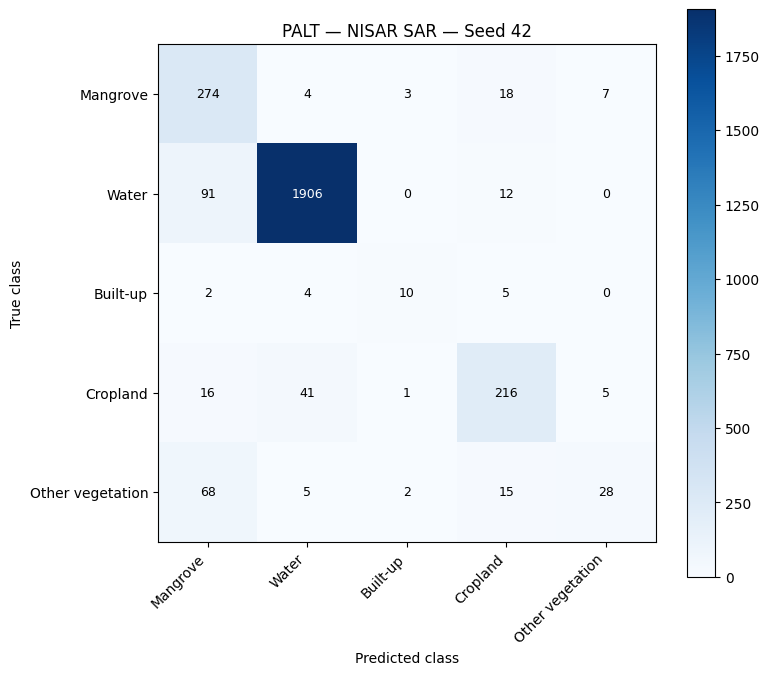

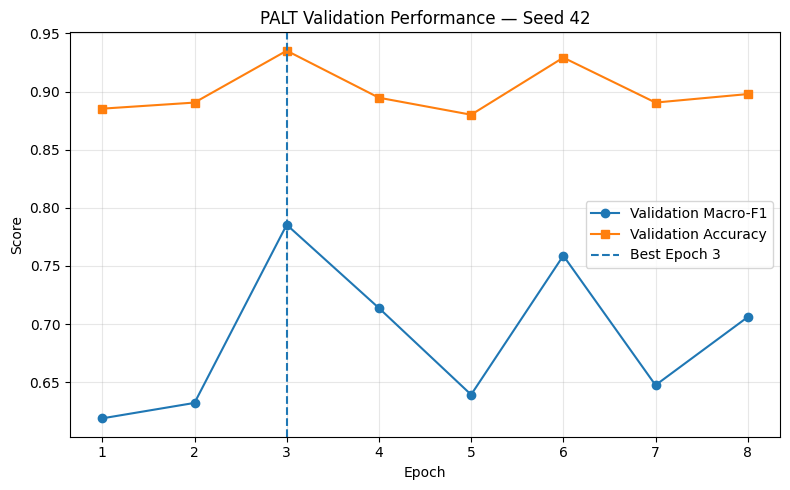


PALT SINGLE-SEED EXPERIMENT COMPLETED
                               0
model                CompactPALT
seed                          42
best_epoch                     3
parameters                208677
accuracy                0.890596
macro_f1                0.674397
balanced_accuracy       0.666366
f1_mangrove              0.72391
f1_water                0.960443
f1_built-up             0.540541
f1_cropland             0.792661
f1_other_vegetation      0.35443

All outputs saved to:
/kaggle/working/NISAR_PALT_PATCH16_REVISED/PALT_seed42


In [24]:

import gc
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. CONFIGURATION: PALT ONLY, SEED 42
# ============================================================

SEED = 42
MAX_EPOCHS = 25
PATIENCE = 5
LR = 3e-4
WEIGHT_DECAY = 1e-4

NUM_CLASSES = 5
CLASS_NAMES = [
    "Mangrove",
    "Water",
    "Built-up",
    "Cropland",
    "Other vegetation"
]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

OUT = Path(
    "/kaggle/working/NISAR_PALT_PATCH16_REVISED/PALT_seed42"
)
OUT.mkdir(parents=True, exist_ok=True)

# Required dataset checks
assert len(train_ds) == 12383
assert len(val_ds) == 2869
assert len(test_ds) == 2733

class_weights = torch.as_tensor(
    class_weights, dtype=torch.float32
)

assert len(class_weights) == NUM_CLASSES
assert torch.isfinite(class_weights).all()

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

print("Device:", DEVICE)
print("Seed:", SEED)
print("Model: CompactPALT")
print("Output:", OUT)

# ============================================================
# 2. PALT ARCHITECTURE
# ============================================================

class CompactPALT(nn.Module):

    def __init__(
        self,
        num_classes=5,
        dim=96,
        heads=4,
        prototypes=16
    ):
        super().__init__()

        # SAR feature extraction
        self.stem = nn.Sequential(
            nn.Conv2d(
                2, 32, 3,
                padding=1, bias=False
            ),
            nn.BatchNorm2d(32),
            nn.GELU(),

            nn.Conv2d(
                32, dim, 3,
                stride=2, padding=1,
                bias=False
            ),
            nn.BatchNorm2d(dim),
            nn.GELU(),

            nn.Conv2d(
                dim, dim, 3,
                stride=2, padding=1,
                bias=False
            ),
            nn.BatchNorm2d(dim),
            nn.GELU()
        )

        # 16x16 input -> 4x4 = 16 tokens
        self.pos = nn.Parameter(
            torch.zeros(1, 16, dim)
        )

        # Self-attention
        self.attn = nn.MultiheadAttention(
            embed_dim=dim,
            num_heads=heads,
            dropout=0.1,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)

        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 2),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(dim * 2, dim)
        )

        # Adaptive prototype memory
        self.prototypes = nn.Parameter(
            torch.randn(prototypes, dim) * 0.02
        )

        self.memory_gate = nn.Sequential(
            nn.Linear(dim * 2, dim),
            nn.Sigmoid()
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Dropout(0.2),
            nn.Linear(dim, num_classes)
        )

    def forward(self, x):

        x = self.stem(x)

        tokens = x.flatten(2).transpose(1, 2)

        if tokens.shape[1] != self.pos.shape[1]:
            raise ValueError(
                "CompactPALT requires 16x16 input patches."
            )

        tokens = tokens + self.pos

        attended, _ = self.attn(
            tokens, tokens, tokens,
            need_weights=False
        )

        tokens = self.norm1(tokens + attended)

        tokens = self.norm2(
            tokens + self.ffn(tokens)
        )

        z = tokens.mean(dim=1)

        # Prototype similarity
        similarity = (
            F.normalize(z, dim=-1)
            @ F.normalize(
                self.prototypes, dim=-1
            ).T
        )

        attention = torch.softmax(
            similarity / 0.2,
            dim=-1
        )

        memory = attention @ self.prototypes

        gate = self.memory_gate(
            torch.cat([z, memory], dim=-1)
        )

        fused = z + gate * memory

        return self.classifier(fused)

# ============================================================
# 3. EVALUATION
# ============================================================

@torch.no_grad()
def evaluate(model, loader):

    model.eval()

    true_labels = []
    predicted_labels = []

    for x, y in loader:

        x = x.to(
            DEVICE, non_blocking=True
        )

        logits = model(x)

        pred = logits.argmax(dim=1)

        true_labels.extend(
            y.cpu().numpy()
        )

        predicted_labels.extend(
            pred.cpu().numpy()
        )

    yt = np.asarray(true_labels)
    yp = np.asarray(predicted_labels)

    labels = np.arange(NUM_CLASSES)

    cm = confusion_matrix(
        yt, yp, labels=labels
    )

    per_class_f1 = f1_score(
        yt, yp,
        labels=labels,
        average=None,
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(yt, yp),
        "macro_f1": f1_score(
            yt, yp,
            labels=labels,
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy":
            balanced_accuracy_score(yt, yp),

        "per_class_f1": per_class_f1,
        "confusion_matrix": cm,
        "y_true": yt,
        "y_pred": yp
    }

# ============================================================
# 4. INITIALIZE PALT
# ============================================================

model = CompactPALT(
    num_classes=NUM_CLASSES,
    dim=96,
    heads=4,
    prototypes=16
).to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(DEVICE)
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("\nPALT PARAMETERS:", total_params)

# ============================================================
# 5. TRAIN PALT: SINGLE SEED 42
# ============================================================

best_f1 = -1.0
best_epoch = 0
wait = 0
history = []

checkpoint = OUT / "PALT_seed42_best.pth"

for epoch in range(1, MAX_EPOCHS + 1):

    model.train()

    loss_sum = 0.0

    for x, y in train_loader:

        x = x.to(
            DEVICE, non_blocking=True
        )

        y = y.to(
            DEVICE, non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        logits = model(x)

        loss = criterion(logits, y)

        loss.backward()

        optimizer.step()

        loss_sum += (
            loss.item() * y.size(0)
        )

    train_loss = loss_sum / len(train_ds)

    # Validation
    val_metrics = evaluate(
        model, val_loader
    )

    val_f1 = val_metrics["macro_f1"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_accuracy":
            val_metrics["accuracy"],
        "val_macro_f1": val_f1,
        "val_balanced_accuracy":
            val_metrics["balanced_accuracy"]
    })

    print(
        f"PALT | Seed 42 | "
        f"Epoch {epoch:02d} | "
        f"Loss {train_loss:.4f} | "
        f"Val Acc {val_metrics['accuracy']:.4f} | "
        f"Val F1 {val_f1:.4f} | "
        f"Val BA "
        f"{val_metrics['balanced_accuracy']:.4f}"
    )

    # Save best validation model
    if val_f1 > best_f1 + 1e-6:

        best_f1 = val_f1
        best_epoch = epoch
        wait = 0

        torch.save({
            "model_state_dict":
                model.state_dict(),
            "model_name": "CompactPALT",
            "seed": SEED,
            "epoch": epoch,
            "val_macro_f1": val_f1,
            "input_bands": ["VVVV", "VHVH"],
            "patch_size": 16,
            "num_classes": NUM_CLASSES,
            "dim": 96,
            "heads": 4,
            "prototypes": 16
        }, checkpoint)

        print("  -> Best checkpoint saved")

    else:
        wait += 1

    if wait >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

# Save training history
history_df = pd.DataFrame(history)

history_df.to_csv(
    OUT / "PALT_seed42_history.csv",
    index=False
)

# ============================================================
# 6. LOAD BEST CHECKPOINT
# ============================================================

saved = torch.load(
    checkpoint,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    saved["model_state_dict"]
)

print("\nBest epoch:", best_epoch)
print("Best validation macro-F1:", best_f1)

# ============================================================
# 7. FINAL TEST EVALUATION
# ============================================================

test_metrics = evaluate(
    model, test_loader
)

print("\n" + "=" * 60)
print("FINAL PALT TEST RESULTS — SEED 42")
print("=" * 60)

print(
    f"Accuracy: "
    f"{test_metrics['accuracy']:.4f}"
)

print(
    f"Macro-F1: "
    f"{test_metrics['macro_f1']:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{test_metrics['balanced_accuracy']:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        test_metrics["y_true"],
        test_metrics["y_pred"],
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

# ============================================================
# 8. SAVE RESULTS
# ============================================================

result = {
    "model": "CompactPALT",
    "seed": SEED,
    "best_epoch": best_epoch,
    "parameters": total_params,
    "accuracy": float(
        test_metrics["accuracy"]
    ),
    "macro_f1": float(
        test_metrics["macro_f1"]
    ),
    "balanced_accuracy": float(
        test_metrics["balanced_accuracy"]
    )
}

for name, value in zip(
    CLASS_NAMES,
    test_metrics["per_class_f1"]
):
    key = (
        "f1_" +
        name.lower().replace(" ", "_")
    )
    result[key] = float(value)

pd.DataFrame([result]).to_csv(
    OUT / "PALT_seed42_test_results.csv",
    index=False
)

with open(
    OUT / "PALT_seed42_results.json", "w"
) as f:
    json.dump(result, f, indent=4)

# Per-class F1
pd.DataFrame({
    "class": CLASS_NAMES,
    "f1": test_metrics["per_class_f1"]
}).to_csv(
    OUT / "PALT_seed42_per_class_f1.csv",
    index=False
)

# Predictions
pd.DataFrame({
    "y_true": test_metrics["y_true"],
    "y_pred": test_metrics["y_pred"]
}).to_csv(
    OUT / "PALT_seed42_predictions.csv",
    index=False
)

# ============================================================
# 9. CONFUSION MATRIX
# ============================================================

cm = test_metrics["confusion_matrix"]

np.save(
    OUT / "PALT_seed42_confusion.npy",
    cm
)

pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    OUT / "PALT_seed42_confusion.csv"
)

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))

ax.set_xticklabels(
    CLASS_NAMES,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(CLASS_NAMES)

ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")

ax.set_title(
    "PALT — NISAR SAR — Seed 42"
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color=(
                "white"
                if cm[i, j] > cm.max() / 2
                else "black"
            ),
            fontsize=9
        )

fig.colorbar(im, ax=ax)
fig.tight_layout()

fig.savefig(
    OUT / "PALT_seed42_confusion.png",
    dpi=300
)

plt.show()
plt.close(fig)

# ============================================================
# 10. TRAINING CURVES
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

ax.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="s",
    label="Validation Accuracy"
)

ax.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch {best_epoch}"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.set_title("PALT Validation Performance — Seed 42")

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    OUT / "PALT_seed42_training_curves.png",
    dpi=300
)

plt.show()
plt.close(fig)

# ============================================================
# 11. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("PALT SINGLE-SEED EXPERIMENT COMPLETED")
print("=" * 60)

print(pd.DataFrame([result]).T)

print("\nAll outputs saved to:")
print(OUT)

del optimizer
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


In [25]:

import os
import time
from pathlib import Path

print("Checking PALT training status...", flush=True)

out = Path(
    "/kaggle/working/NISAR_PALT_PATCH16_REVISED/PALT_seed42"
)

print("Output folder exists:", out.exists(), flush=True)

if out.exists():
    for f in sorted(out.iterdir()):
        print(
            f.name,
            "| Size:",
            round(f.stat().st_size / 1024 / 1024, 2),
            "MB",
            flush=True
        )

print("\nGPU status:", flush=True)
os.system("nvidia-smi")


Checking PALT training status...
Output folder exists: True
PALT_seed42_best.pth | Size: 0.81 MB
PALT_seed42_confusion.csv | Size: 0.0 MB
PALT_seed42_confusion.npy | Size: 0.0 MB
PALT_seed42_confusion.png | Size: 0.17 MB
PALT_seed42_history.csv | Size: 0.0 MB
PALT_seed42_per_class_f1.csv | Size: 0.0 MB
PALT_seed42_predictions.csv | Size: 0.01 MB
PALT_seed42_results.json | Size: 0.0 MB
PALT_seed42_test_results.csv | Size: 0.0 MB
PALT_seed42_training_curves.png | Size: 0.17 MB

GPU status:
Mon Oct 26 08:13:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|              

0

In [26]:

# ============================================================
# PALT SEED 42 — DISPLAY RESULTS IN NOTEBOOK OUTPUT
# ============================================================

print("=" * 65)
print("       NISAR SAR — PALT FINAL RESULTS (SEED 42)")
print("=" * 65)

print(f"Model              : CompactPALT")
print(f"Seed               : {SEED}")
print(f"Best Epoch         : {best_epoch}")
print(f"Total Parameters   : {total_params:,}")

print("\n--- OVERALL TEST PERFORMANCE ---")
print(f"Accuracy           : {test_metrics['accuracy']*100:.2f}%")
print(f"Macro-F1           : {test_metrics['macro_f1']*100:.2f}%")
print(f"Balanced Accuracy  : {test_metrics['balanced_accuracy']*100:.2f}%")

print("\n--- PER-CLASS F1 SCORES ---")
for name, score in zip(
    CLASS_NAMES, test_metrics["per_class_f1"]
):
    print(f"{name:<20}: {score*100:.2f}%")

print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(
    test_metrics["y_true"],
    test_metrics["y_pred"],
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

print("\n--- CONFUSION MATRIX ---")
print(pd.DataFrame(
    test_metrics["confusion_matrix"],
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_string())

print("\n--- EPOCH-WISE TRAINING HISTORY ---")
print(history_df.to_string(index=False))

print("\n" + "=" * 65)
print("PALT SEED 42 EVALUATION COMPLETED")
print("=" * 65)


       NISAR SAR — PALT FINAL RESULTS (SEED 42)
Model              : CompactPALT
Seed               : 42
Best Epoch         : 3
Total Parameters   : 208,677

--- OVERALL TEST PERFORMANCE ---
Accuracy           : 89.06%
Macro-F1           : 67.44%
Balanced Accuracy  : 66.64%

--- PER-CLASS F1 SCORES ---
Mangrove            : 72.39%
Water               : 96.04%
Built-up            : 54.05%
Cropland            : 79.27%
Other vegetation    : 35.44%

--- CLASSIFICATION REPORT ---
                  precision    recall  f1-score   support

        Mangrove     0.6075    0.8954    0.7239       306
           Water     0.9724    0.9487    0.9604      2009
        Built-up     0.6250    0.4762    0.5405        21
        Cropland     0.8120    0.7742    0.7927       279
Other vegetation     0.7000    0.2373    0.3544       118

        accuracy                         0.8906      2733
       macro avg     0.7434    0.6664    0.6744      2733
    weighted avg     0.9008    0.8906    0.8874      2